# Лабораторная работа: самописный MLP на CPU

Цель: написать многослойный перцептрон на NumPy (без PyTorch и других библиотек для нейросетей), обучить его алгоритмом обратного распространения ошибки с mini-batches и оценить качество на отложенной выборке.

Я выбрал задачу бинарной классификации на датасете Breast Cancer Wisconsin (Diagnostic). Из sklearn беру только загрузку данных, разбиение, стандартизацию и готовые функции метрик, сама сеть и обучение написаны вручную.

**Выполнил:** Фролов А.А., 3 курс, группа ИВТ-2.3
**Дисциплина:** Математика для ИИ, лабораторная работа №5

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
)

np.random.seed(42)

## 1. Датасет

Breast Cancer Wisconsin (Diagnostic), репозиторий UCI: https://archive.ics.uci.edu/dataset/17/breast+cancer+wisconsin+diagnostic. Этот же датасет встроен в sklearn (`load_breast_cancer`), поэтому отдельно ничего скачивать не нужно.

Один объект — это снимок клеток опухоли молочной железы. Признаков 30, все числовые: для 10 характеристик ядра клетки (радиус, текстура, периметр, площадь, гладкость и т.д.) посчитаны среднее, стандартная ошибка и худшее значение. Цель одна — диагноз: злокачественная опухоль (M) или доброкачественная (B).

В sklearn метка 0 означает злокачественную опухоль, а 1 — доброкачественную. Мне удобнее наоборот, чтобы классом 1 была болезнь, поэтому перекодирую: M → 1, B → 0.

In [2]:
data = load_breast_cancer()
X = data.data
y = 1 - data.target  # 1 = злокачественная (M), 0 = доброкачественная (B)

print("Размер матрицы признаков:", X.shape)
print("Объектов класса 0 (B):", int(np.sum(y == 0)))
print("Объектов класса 1 (M):", int(np.sum(y == 1)))
print("Первые признаки:", ", ".join(data.feature_names[:5]))

Размер матрицы признаков: (569, 30)
Объектов класса 0 (B): 357
Объектов класса 1 (M): 212
Первые признаки: mean radius, mean texture, mean perimeter, mean area, mean smoothness


In [3]:
df = pd.DataFrame(X, columns=data.feature_names)
df.iloc[:, :6].describe().round(2)

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness
count,569.00,569.00,569.00,569.00,569.00,569.00
mean,14.13,19.29,91.97,654.89,0.10,0.10
std,3.52,4.30,24.30,351.91,0.01,0.05
min,6.98,9.71,43.79,143.50,0.05,0.02
25%,11.70,16.17,75.17,420.30,0.09,0.06
50%,13.37,18.84,86.24,551.10,0.10,0.09
75%,15.78,21.80,104.10,782.70,0.11,0.13
max,28.11,39.28,188.50,2501.00,0.16,0.35


В датасете 569 объектов и 30 признаков, пропусков нет. Доброкачественных опухолей 357, злокачественных 212, то есть класс 1 составляет примерно 37 %. По таблице видно, что признаки сильно отличаются по масштабу: площадь (`mean area`) в среднем около 655, а гладкость (`mean smoothness`) около 0.1. Поэтому перед обучением признаки нужно стандартизировать.

## 2. Предобработка

Делю данные на train/val/test в пропорции 60/20/20 со стратификацией, чтобы доля классов во всех частях была одинаковой. Сначала отделяю 40 %, потом делю их пополам.

Признаки стандартизирую: вычитаю среднее и делю на стандартное отклонение. Среднее и отклонение считаю только по train, а к val и test применяю уже готовые, иначе информация из теста попала бы в обучение.

In [4]:
X_train, X_rest, y_train, y_rest = train_test_split(
    X, y, test_size=0.4, stratify=y, random_state=42
)
X_val, X_test, y_val, y_test = train_test_split(
    X_rest, y_rest, test_size=0.5, stratify=y_rest, random_state=42
)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_val = scaler.transform(X_val)
X_test = scaler.transform(X_test)

for name, X_part, y_part in [("train", X_train, y_train), ("val", X_val, y_val), ("test", X_test, y_test)]:
    print(f"{name}: {X_part.shape[0]} объектов, доля класса 1 = {y_part.mean():.3f}")

train: 341 объектов, доля класса 1 = 0.372
val: 114 объектов, доля класса 1 = 0.377
test: 114 объектов, доля класса 1 = 0.368


В материалах по алгоритму объекты лежат в столбцах: матрица входа имеет размер (число признаков, размер батча). В sklearn наоборот, объекты в строках. Чтобы формулы совпадали с материалами, транспонирую матрицы признаков.

In [5]:
X_train = X_train.T
X_val = X_val.T
X_test = X_test.T

print("X_train:", X_train.shape)
print("X_val:  ", X_val.shape)
print("X_test: ", X_test.shape)

X_train: (30, 341)
X_val:   (30, 114)
X_test:  (30, 114)


## 3. Модель

Архитектура: 30 входов → 64 нейрона (ReLU) → 32 нейрона (ReLU) → 1 нейрон (сигмоида). Выход сети $\hat p \in (0, 1)$ — оценка вероятности класса 1.

Функция потерь — бинарная кросс-энтропия:

$$E = -\frac{1}{|B|}\sum_{i}\big(y_i \ln \hat p_i + (1 - y_i)\ln(1 - \hat p_i)\big)$$

Формулы для одного мини-батча $B$ (слои $L = 1, \dots, H$, $A^0 = X_B$):

- прямой проход: $Z^L = W^L A^{L-1} + b^L$, $A^L = h_L(Z^L)$;
- ошибка выходного слоя: для сигмоиды с кросс-энтропией получается $\Delta^H = A^H - Y_B$;
- ошибка скрытого слоя: $\Delta^L = (W^{L+1})^\top \Delta^{L+1} \odot h_L'(Z^L)$;
- градиенты: $\nabla_{W^L} E = \frac{1}{|B|}\Delta^L (A^{L-1})^\top + \lambda W^L$, $\nabla_{b^L} E = \frac{1}{|B|}\Delta^L \mathbf{1}$;
- шаг: $W^L \leftarrow W^L - \eta \nabla_{W^L} E$, $b^L \leftarrow b^L - \eta \nabla_{b^L} E$.

Слагаемое $\lambda W^L$ — это L2-регуляризация, она штрафует большие веса. На смещения регуляризацию не накладываю.

In [6]:
def relu(Z):
    return np.maximum(0, Z)


def relu_derivative(Z):
    return (Z > 0).astype(float)


def sigmoid(Z):
    return 1 / (1 + np.exp(-Z))


def bce_loss(y_true, p):
    # маленькая добавка, чтобы не брать логарифм нуля
    eps = 1e-8
    return float(-np.mean(y_true * np.log(p + eps) + (1 - y_true) * np.log(1 - p + eps)))

In [7]:
class MLP:
    def __init__(self, layer_sizes, learning_rate=0.05, l2=0.001):
        self.L = len(layer_sizes) - 1  # число слоёв с весами
        self.learning_rate = learning_rate
        self.l2 = l2
        self.params = {}
        for l in range(1, self.L + 1):
            n_in = layer_sizes[l - 1]
            n_out = layer_sizes[l]
            # инициализация He для слоёв с ReLU
            self.params[f"W{l}"] = np.random.randn(n_out, n_in) * np.sqrt(2 / n_in)
            self.params[f"b{l}"] = np.zeros((n_out, 1))

    def forward(self, X):
        A_cache = {"A0": X}
        Z_cache = {}
        A = X
        for l in range(1, self.L + 1):
            Z = np.dot(self.params[f"W{l}"], A) + self.params[f"b{l}"]
            if l < self.L:
                A = relu(Z)      # скрытые слои
            else:
                A = sigmoid(Z)   # выходной слой
            Z_cache[f"Z{l}"] = Z
            A_cache[f"A{l}"] = A
        return A_cache, Z_cache

    def backward(self, y, A_cache, Z_cache):
        grads = {}
        m = len(y)
        Y = y.reshape(1, m)

        # ошибка выходного слоя
        dZ = A_cache[f"A{self.L}"] - Y

        for l in range(self.L, 0, -1):
            A_prev = A_cache[f"A{l - 1}"]
            W = self.params[f"W{l}"]
            grads[f"dW{l}"] = np.dot(dZ, A_prev.T) / m + self.l2 * W
            grads[f"db{l}"] = np.sum(dZ, axis=1, keepdims=True) / m
            if l > 1:
                # передаём ошибку на предыдущий слой
                dA = np.dot(W.T, dZ)
                dZ = dA * relu_derivative(Z_cache[f"Z{l - 1}"])
        return grads

    def update(self, grads):
        for l in range(1, self.L + 1):
            self.params[f"W{l}"] -= self.learning_rate * grads[f"dW{l}"]
            self.params[f"b{l}"] -= self.learning_rate * grads[f"db{l}"]

    def predict_proba(self, X):
        A_cache, _ = self.forward(X)
        return A_cache[f"A{self.L}"].ravel()

    def predict(self, X, threshold=0.5):
        return (self.predict_proba(X) >= threshold).astype(int)

Проверяю размерности на необученной сети: веса слоя должны иметь размер (нейронов в слое, нейронов в предыдущем слое), а выход — по одной вероятности на объект.

In [8]:
test_model = MLP([30, 64, 32, 1])
for name, value in test_model.params.items():
    print(name, value.shape)

p = test_model.predict_proba(X_train[:, :5])
print("Вероятности для 5 объектов:", np.round(p, 3))
print("Loss необученной сети на train:", round(bce_loss(y_train, test_model.predict_proba(X_train)), 4))

W1 (64, 30)
b1 (64, 1)
W2 (32, 64)
b2 (32, 1)
W3 (1, 32)
b3 (1, 1)
Вероятности для 5 объектов: [0.758 0.805 0.688 0.969 0.981]
Loss необученной сети на train: 1.1307


## 4. Обучение

Функция `log_epoch_metrics` добавляет в историю одну строку за эпоху. Функция `train` на каждой эпохе перемешивает обучающую выборку, идёт по мини-батчам (forward → backward → обновление весов), а после эпохи считает loss и метрику на train и val.

Ранняя остановка: запоминаю веса с лучшим `val_loss`. Если `val_loss` не улучшается `patience` эпох подряд, обучение прекращается и в модель возвращаются лучшие веса.

In [9]:
def log_epoch_metrics(history, epoch, loss, val_loss, metric, val_metric, metric_name="metric"):
    history.append({
        "epoch": epoch,
        "loss": loss,
        "val_loss": val_loss,
        metric_name: metric,
        f"val_{metric_name}": val_metric,
    })
    return history


def train(model, X_train, y_train, X_val, y_val,
          epochs=50, batch_size=32, metric_fn=None, metric_name="metric", patience=15):
    history = []
    m = X_train.shape[1]
    best_val_loss = None
    best_params = None
    best_epoch = 0
    bad_epochs = 0

    for epoch in range(1, epochs + 1):
        # перемешиваем объекты в начале эпохи
        permutation = np.random.permutation(m)
        X_shuffled = X_train[:, permutation]
        y_shuffled = y_train[permutation]

        for i in range(0, m, batch_size):
            X_batch = X_shuffled[:, i:i + batch_size]
            y_batch = y_shuffled[i:i + batch_size]

            A_cache, Z_cache = model.forward(X_batch)
            grads = model.backward(y_batch, A_cache, Z_cache)
            model.update(grads)

        loss = bce_loss(y_train, model.predict_proba(X_train))
        metric = metric_fn(y_train, model.predict(X_train))

        val_loss = bce_loss(y_val, model.predict_proba(X_val))
        val_metric = metric_fn(y_val, model.predict(X_val))

        history = log_epoch_metrics(history, epoch, loss, val_loss,
                                    metric, val_metric, metric_name)

        # ранняя остановка по val_loss
        if best_val_loss is None or val_loss < best_val_loss:
            best_val_loss = val_loss
            best_epoch = epoch
            best_params = {name: value.copy() for name, value in model.params.items()}
            bad_epochs = 0
        else:
            bad_epochs += 1
            if bad_epochs >= patience:
                print(f"Ранняя остановка на эпохе {epoch}")
                break

    model.params = best_params
    print(f"Лучшая эпоха: {best_epoch}, val_loss = {best_val_loss:.4f}")
    return pd.DataFrame(history)

Гиперпараметры: скорость обучения $\eta = 0.05$, коэффициент L2 $\lambda = 0.001$, размер батча 32, максимум 100 эпох, `patience = 15`. Оптимизатор — обычный SGD без момента.

In [10]:
np.random.seed(42)

model = MLP([30, 64, 32, 1], learning_rate=0.05, l2=0.001)

history_df = train(model, X_train, y_train, X_val, y_val,
                   epochs=100, batch_size=32,
                   metric_fn=accuracy_score, metric_name="accuracy", patience=15)

print("Всего эпох:", len(history_df))
history_df.head()

Ранняя остановка на эпохе 41
Лучшая эпоха: 26, val_loss = 0.0565
Всего эпох: 41


,epoch,loss,val_loss,accuracy,val_accuracy
0,1,0.269265,0.227586,0.929619,0.929825
1,2,0.189278,0.148503,0.941349,0.947368
2,3,0.156121,0.118656,0.956012,0.947368
3,4,0.136512,0.103343,0.961877,0.964912
4,5,0.122576,0.092696,0.967742,0.964912


In [11]:
history_df.tail()

,epoch,loss,val_loss,accuracy,val_accuracy
36,37,0.037068,0.056952,0.991202,0.964912
37,38,0.036275,0.057268,0.991202,0.964912
38,39,0.035608,0.056672,0.991202,0.964912
39,40,0.034811,0.057096,0.991202,0.964912
40,41,0.034123,0.057635,0.991202,0.964912


## 5. Кривые обучения

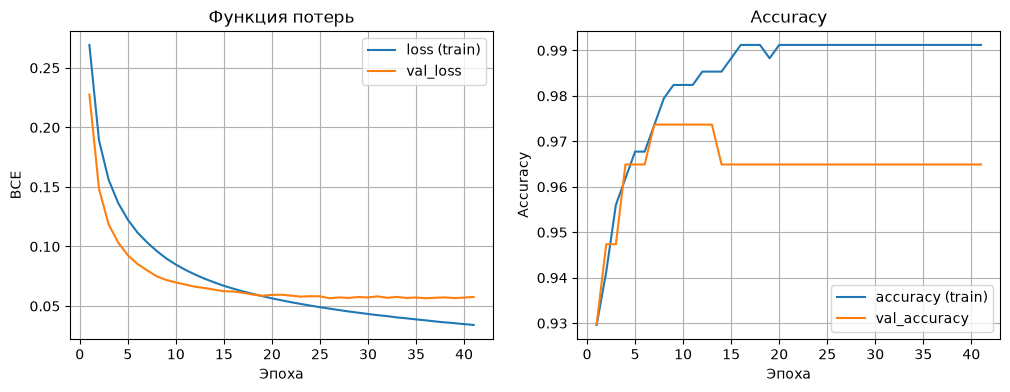

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(history_df["epoch"], history_df["loss"], label="loss (train)")
axes[0].plot(history_df["epoch"], history_df["val_loss"], label="val_loss")
axes[0].set_title("Функция потерь")
axes[0].set_xlabel("Эпоха")
axes[0].set_ylabel("BCE")
axes[0].grid(True)
axes[0].legend()

axes[1].plot(history_df["epoch"], history_df["accuracy"], label="accuracy (train)")
axes[1].plot(history_df["epoch"], history_df["val_accuracy"], label="val_accuracy")
axes[1].set_title("Accuracy")
axes[1].set_xlabel("Эпоха")
axes[1].set_ylabel("Accuracy")
axes[1].grid(True)
axes[1].legend()

plt.show()

Loss на обучении падает всё время: с 0.269 на первой эпохе до 0.034 на последней. Loss на валидации сначала тоже быстро падает (0.228 на первой эпохе), достигает минимума 0.0565 на 26-й эпохе, а дальше перестаёт улучшаться и держится около 0.057. Через 15 эпох без улучшения сработала ранняя остановка, обучение закончилось на 41-й эпохе вместо 100, а в модель вернулись веса 26-й эпохи.

К концу accuracy на обучении равна 0.991, а на валидации 0.965. Разрыв между train и val небольшой, но он растёт, так что дальше сеть начала бы переобучаться. Ранняя остановка и L2-регуляризация как раз от этого и защищают.

## 6. Подбор порога $\tau$

Сеть выдаёт вероятность $\hat p$, а класс получается по правилу $\hat y = 1$, если $\hat p \ge \tau$. В обучении порог не участвует, это отдельный гиперпараметр. Подбираю его на валидации: перебираю значения от 0.05 до 0.95 с шагом 0.05 и беру то, при котором F1 максимальна. Тестовую выборку на этом шаге не трогаю.

Выбрал F1, потому что классы не совсем сбалансированы и важно одновременно не пропускать больных (recall) и не поднимать ложную тревогу (precision).

In [13]:
p_val = model.predict_proba(X_val)

thresholds = np.round(np.arange(0.05, 0.96, 0.05), 2)
f1_values = []
for t in thresholds:
    y_pred = (p_val >= t).astype(int)
    f1_values.append(f1_score(y_val, y_pred))

threshold_df = pd.DataFrame({"tau": thresholds, "f1_val": np.round(f1_values, 4)})
best_tau = float(thresholds[int(np.argmax(f1_values))])

print("Лучший порог:", best_tau)
print("F1 на val при этом пороге:", round(max(f1_values), 4))
print("F1 на val при пороге 0.5:", round(f1_score(y_val, (p_val >= 0.5).astype(int)), 4))
threshold_df

Лучший порог: 0.25
F1 на val при этом пороге: 1.0
F1 на val при пороге 0.5: 0.9512


,tau,f1_val
0,0.05,0.9348
1,0.10,0.9663
2,0.15,0.9773
3,0.20,0.9885
4,0.25,1.0000
5,0.30,0.9882
6,0.35,0.9882
7,0.40,0.9639
8,0.45,0.9639
9,0.50,0.9512


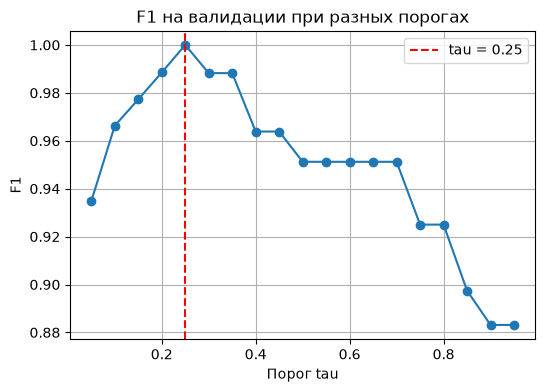

In [14]:
plt.figure(figsize=(6, 4))
plt.plot(thresholds, f1_values, marker="o")
plt.axvline(best_tau, color="red", linestyle="--", label=f"tau = {best_tau}")
plt.title("F1 на валидации при разных порогах")
plt.xlabel("Порог tau")
plt.ylabel("F1")
plt.grid(True)
plt.legend()
plt.show()

Максимум F1 на валидации получился при $\tau = 0.25$: F1 = 1.0, то есть на валидации при таком пороге ошибок нет. При стандартном пороге 0.5 F1 = 0.9512. При порогах выше 0.7 F1 заметно падает, потому что сеть начинает пропускать злокачественные опухоли.

Беру $\tau = 0.25$. Порог ниже 0.5 здесь выглядит разумно и по смыслу задачи: пропустить злокачественную опухоль хуже, чем лишний раз отправить человека на дополнительное обследование.

## 7. Метрики на тестовой выборке

Accuracy и F1 зависят от порога, поэтому считаю их для $\tau = 0.5$ и для выбранного порога. ROC-AUC и PR-AUC считаются по вероятностям и от порога не зависят.

In [15]:
p_test = model.predict_proba(X_test)

rows = []
for t in [0.5, best_tau]:
    y_pred = (p_test >= t).astype(int)
    rows.append({
        "tau": t,
        "accuracy": round(accuracy_score(y_test, y_pred), 4),
        "f1": round(f1_score(y_test, y_pred), 4),
        "precision": round(precision_score(y_test, y_pred), 4),
        "recall": round(recall_score(y_test, y_pred), 4),
    })

print("ROC-AUC:", round(roc_auc_score(y_test, p_test), 4))
print("PR-AUC: ", round(average_precision_score(y_test, p_test), 4))
pd.DataFrame(rows)

ROC-AUC: 0.994
PR-AUC:  0.9923


,tau,accuracy,f1,precision,recall
0,0.50,0.9825,0.9756,1.0000,0.9524
1,0.25,0.9649,0.9535,0.9318,0.9762


In [16]:
y_pred_test = (p_test >= best_tau).astype(int)
cm = confusion_matrix(y_test, y_pred_test)

pd.DataFrame(cm,
             index=["факт: B (0)", "факт: M (1)"],
             columns=["прогноз: B (0)", "прогноз: M (1)"])

,прогноз: B (0),прогноз: M (1)
факт: B (0),69,3
факт: M (1),1,41


На тесте ROC-AUC = 0.994 и PR-AUC = 0.9923, то есть сеть почти всегда даёт злокачественным опухолям вероятность выше, чем доброкачественным.

При выбранном пороге $\tau = 0.25$ accuracy = 0.9649 и F1 = 0.9535. По матрице ошибок из 114 объектов ошибок 4: одна злокачественная опухоль пропущена и три доброкачественные приняты за злокачественные. При пороге 0.5 результат на тесте немного лучше: accuracy = 0.9825, F1 = 0.9756, ложных тревог нет, но пропущенных опухолей уже две (recall 0.9524 против 0.9762).

Получается, что порог, идеальный на валидации, на тесте не дал прироста F1. Валидационная выборка маленькая (114 объектов), и значение F1 = 1.0 на ней отчасти случайное. Но свою задачу порог 0.25 выполнил: пропущенных больных стало меньше, за это заплатили тремя ложными тревогами.

## 8. Итог

ИТОГ